In [116]:
import pandas as pd 
import numpy as np 
import warnings 
warnings.filterwarnings("ignore")

Data has been collected from UC Irvine and originally has 2.07 million rows and 9 columns. Measurements of electric power consumption in just one household with a one-minute sampling rate over a period in Dec.2006 to Nov.2010. It shows different electrical quantities and some sub-metering values which kitchen stuffs, laundry room and water heater and air conditioner. This data represents household electricity consumption by one household usage so it will be include housing data category. The data uploaded has 1.04 million rows, 9 columns for two years due to computer did not have enough raw. In the future, results will be based on the uploaded data.
Household electricity consumption patterns have been identified by clusters, and electricity consumption is projected to increase until 2028 by time series model.  


In [117]:
df=pd.read_csv("individual household power consumption.csv", sep=";")

In [118]:
df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.0


In [119]:
df.shape

(1048575, 9)

In [120]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 9 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   Date                   1048575 non-null  object 
 1   Time                   1048575 non-null  object 
 2   Global_active_power    1048575 non-null  object 
 3   Global_reactive_power  1048575 non-null  object 
 4   Voltage                1048575 non-null  object 
 5   Global_intensity       1048575 non-null  object 
 6   Sub_metering_1         1048575 non-null  object 
 7   Sub_metering_2         1048575 non-null  object 
 8   Sub_metering_3         1044506 non-null  float64
dtypes: float64(1), object(8)
memory usage: 72.0+ MB


In [121]:
df.isnull().sum()

Date                        0
Time                        0
Global_active_power         0
Global_reactive_power       0
Voltage                     0
Global_intensity            0
Sub_metering_1              0
Sub_metering_2              0
Sub_metering_3           4069
dtype: int64

In [122]:
df["Global_active_power"].unique()

array(['4.216', '5.360', '5.374', ..., '7.400', '7.338', '7.380'],
      shape=(4076,), dtype=object)

In [123]:
df["Global_reactive_power"].unique()

array(['0.418', '0.436', '0.498', '0.502', '0.528', '0.522', '0.520',
       '0.510', '0.470', '0.478', '0.398', '0.422', '0.282', '0.152',
       '0.156', '0.000', '0.076', '0.090', '0.200', '0.058', '0.180',
       '0.144', '0.118', '0.108', '0.202', '0.192', '0.186', '0.116',
       '0.136', '0.148', '0.160', '0.158', '0.100', '0.082', '0.050',
       '0.052', '0.162', '0.086', '0.048', '0.054', '0.068', '0.166',
       '0.174', '0.178', '0.188', '0.088', '0.080', '0.070', '0.084',
       '0.074', '0.106', '0.092', '0.064', '0.046', '0.138', '0.134',
       '0.132', '0.120', '0.130', '0.154', '0.078', '0.142', '0.140',
       '0.146', '0.150', '0.170', '0.102', '0.072', '0.060', '0.056',
       '0.062', '0.112', '0.066', '0.172', '0.168', '0.194', '0.184',
       '0.096', '0.164', '0.182', '0.094', '0.098', '0.176', '0.190',
       '0.204', '0.220', '0.198', '0.208', '0.244', '0.334', '0.298',
       '0.296', '0.286', '0.278', '0.104', '0.258', '0.238', '0.256',
       '0.214', '0.2

In [124]:
df["Voltage"].unique()

array(['234.840', '233.630', '233.290', ..., '250.450', '250.470',
       '250.690'], shape=(2605,), dtype=object)

In [125]:
df["Global_intensity"].unique()

array(['18.400', '23.000', '15.800', '15.000', '19.600', '23.200',
       '22.400', '22.600', '17.600', '14.200', '13.800', '14.400',
       '16.400', '25.400', '33.200', '30.600', '22.000', '19.400',
       '13.600', '13.400', '11.600', '19.200', '10.400', '11.800',
       '11.000', '21.000', '26.200', '29.000', '27.800', '27.000',
       '19.000', '9.600', '10.000', '21.400', '17.800', '12.000',
       '12.400', '15.200', '20.800', '15.600', '26.400', '18.800',
       '13.000', '9.800', '9.200', '13.200', '18.000', '10.800', '10.600',
       '18.200', '17.000', '17.400', '14.800', '14.600', '15.400',
       '14.000', '8.400', '9.400', '7.800', '8.200', '8.600', '11.400',
       '12.600', '9.000', '7.600', '12.800', '7.400', '5.600', '4.600',
       '7.200', '1.600', '2.400', '2.800', '1.200', '4.400', '4.000',
       '10.200', '6.800', '5.200', '6.000', '6.600', '8.000', '2.000',
       '4.800', '5.400', '16.600', '3.000', '1.800', '8.800', '1.400',
       '21.800', '20.200', '16.000

In [126]:
df["Sub_metering_1"].unique()

array(['0.000', '1.000', '2.000', '6.000', '37.000', '36.000', '38.000',
       '25.000', '12.000', '11.000', '9.000', '4.000', '33.000', '5.000',
       '34.000', '8.000', '26.000', '27.000', '15.000', '20.000',
       '21.000', '23.000', '16.000', '10.000', '39.000', '32.000', '?',
       '19.000', '35.000', '30.000', '40.000', '7.000', '31.000',
       '17.000', '3.000', '29.000', '24.000', '14.000', '41.000',
       '53.000', '76.000', '75.000', '77.000', '74.000', '28.000',
       '68.000', '58.000', '62.000', '13.000', '18.000', '22.000',
       '64.000', '71.000', '56.000', '72.000', '45.000', '42.000',
       '59.000', '66.000', '43.000', '44.000', '48.000', '46.000',
       '73.000', '55.000', '60.000', '70.000', '63.000', '67.000',
       '47.000', '65.000', '51.000', '50.000', '69.000', '78.000',
       '57.000', '49.000', '61.000', '52.000', '54.000', '79.000',
       '80.000'], dtype=object)

In [127]:
df["Sub_metering_2"].unique()

array(['1.000', '2.000', '0.000', '16.000', '37.000', '36.000', '22.000',
       '12.000', '27.000', '20.000', '9.000', '4.000', '3.000', '5.000',
       '13.000', '35.000', '28.000', '26.000', '24.000', '21.000',
       '17.000', '33.000', '25.000', '23.000', '18.000', '30.000',
       '31.000', '7.000', '38.000', '29.000', '50.000', '71.000',
       '59.000', '62.000', '70.000', '40.000', '34.000', '8.000',
       '15.000', '6.000', '32.000', '19.000', '14.000', '49.000',
       '72.000', '73.000', '61.000', '39.000', '42.000', '10.000',
       '56.000', '11.000', '?', '43.000', '67.000', '63.000', '53.000',
       '65.000', '52.000', '69.000', '48.000', '74.000', '41.000',
       '47.000', '58.000', '68.000', '64.000', '75.000', '46.000',
       '57.000', '60.000', '66.000', '44.000', '78.000', '77.000',
       '76.000', '51.000', '55.000', '45.000', '54.000'], dtype=object)

In [128]:
df["Sub_metering_3"].unique()

array([17., 16., 18.,  9.,  0.,  5., 19., 10., 20.,  8.,  4.,  2.,  3.,
       11., 13.,  6., 15., nan, 12.,  1., 14.,  7., 23., 25., 26., 28.,
       27., 21., 22., 29., 24., 30., 31.])

In [129]:
mv=["nan", "...,", "?"]

In [130]:
df=pd.read_csv("individual household power consumption.csv",sep=";", na_values=mv)

In [131]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 9 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   Date                   1048575 non-null  object 
 1   Time                   1048575 non-null  object 
 2   Global_active_power    1044506 non-null  float64
 3   Global_reactive_power  1044506 non-null  float64
 4   Voltage                1044506 non-null  float64
 5   Global_intensity       1044506 non-null  float64
 6   Sub_metering_1         1044506 non-null  float64
 7   Sub_metering_2         1044506 non-null  float64
 8   Sub_metering_3         1044506 non-null  float64
dtypes: float64(7), object(2)
memory usage: 72.0+ MB


In [132]:
 df["Global_active_power"].fillna(df["Global_active_power"].median(), inplace=True)
 df["Global_reactive_power"].fillna(df["Global_reactive_power"].median(), inplace=True)
 df["Voltage"].fillna(df["Voltage"].median(), inplace=True)
 df["Global_intensity"].fillna(df["Global_intensity"].median(), inplace=True)
 df["Sub_metering_1"].fillna(df["Sub_metering_1"].median(), inplace=True)
 df["Sub_metering_2"].fillna(df["Sub_metering_2"].median(), inplace=True)
 df["Sub_metering_3"].fillna(df["Sub_metering_3"].median(), inplace=True)

In [133]:
df.isnull().sum()

Date                     0
Time                     0
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64

In [134]:
def categorize_time(hour):
    if 5<=hour<12:
        return "Morning"
    elif 12<=hour <17:
        return "Afternoon"
    elif 17 <=hour <21:
        return "Evening"
    else:
        return "Night"
df["Hour"]=pd.to_datetime(df["Time"]).dt.hour
df["Period"]=df["Hour"].apply(categorize_time)

In [135]:
df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Hour,Period
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0,17,Evening
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0,17,Evening
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0,17,Evening
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0,17,Evening
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0,17,Evening


In [136]:
import sklearn.preprocessing as preproc
df["Global_active_power"]=preproc.StandardScaler().fit_transform(df[["Global_active_power"]])
df["Global_reactive_power"]=preproc.StandardScaler().fit_transform(df[["Global_reactive_power"]])
df["Voltage"]=preproc.StandardScaler().fit_transform(df[["Voltage"]])
df["Global_intensity"]=preproc.StandardScaler().fit_transform(df[["Global_intensity"]])
df["Sub_metering_1"]=preproc.StandardScaler().fit_transform(df[["Sub_metering_1"]])
df["Sub_metering_2"]=preproc.StandardScaler().fit_transform(df[["Sub_metering_2"]])
df["Sub_metering_3"]=preproc.StandardScaler().fit_transform(df[["Sub_metering_3"]])

In [137]:
df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Hour,Period
0,16/12/2006,17:24:00,2.757340,2.742941,-1.562088,2.878339,-0.185897,-0.074034,1.351887,17,Evening
1,16/12/2006,17:25:00,3.771627,2.907624,-1.931197,3.845433,-0.185897,-0.074034,1.229977,17,Evening
2,16/12/2006,17:26:00,3.784040,3.474867,-2.034914,3.845433,-0.185897,0.083669,1.351887,17,Evening
3,16/12/2006,17:27:00,3.796452,3.511463,-1.897642,3.845433,-0.185897,-0.074034,1.351887,17,Evening
4,16/12/2006,17:28:00,2.269702,3.749339,-1.305846,2.331721,-0.185897,-0.074034,1.351887,17,Evening


In [138]:
df.drop(columns=["Date"], inplace=True)
df.drop(columns=["Time"], inplace=True)

In [139]:
df.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Hour,Period
0,2.757340,2.742941,-1.562088,2.878339,-0.185897,-0.074034,1.351887,17,Evening
1,3.771627,2.907624,-1.931197,3.845433,-0.185897,-0.074034,1.229977,17,Evening
2,3.784040,3.474867,-2.034914,3.845433,-0.185897,0.083669,1.351887,17,Evening
3,3.796452,3.511463,-1.897642,3.845433,-0.185897,-0.074034,1.351887,17,Evening
4,2.269702,3.749339,-1.305846,2.331721,-0.185897,-0.074034,1.351887,17,Evening


In [140]:
df.drop(columns=["Hour"], inplace=True)

In [147]:
le=preproc.LabelEncoder()
df["Period"]=le.fit_transform(df["Period"])

In [149]:
df["Period"].unique()

array([1, 3, 2, 0])

In [150]:
df.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Period
0,2.757340,2.742941,-1.562088,2.878339,-0.185897,-0.074034,1.351887,1
1,3.771627,2.907624,-1.931197,3.845433,-0.185897,-0.074034,1.229977,1
2,3.784040,3.474867,-2.034914,3.845433,-0.185897,0.083669,1.351887,1
3,3.796452,3.511463,-1.897642,3.845433,-0.185897,-0.074034,1.351887,1
4,2.269702,3.749339,-1.305846,2.331721,-0.185897,-0.074034,1.351887,1


K-means Clustering

In [151]:
df_sampled=df.sample(n=1000, random_state=42)
x=df_sampled.iloc[:, 0:7].values
print(x)

[[-0.64903398  0.12630736  0.94541616 ... -0.18589653 -0.23173732
  -0.59867864]
 [ 2.04982136  3.0357112  -0.07649835 ... -0.18589653 -0.23173732
   1.59570777]
 [-0.75365452 -0.07497215  0.28651009 ... -0.18589653  0.08366905
  -0.59867864]
 ...
 [-0.65080721  0.41907756  1.14979907 ... -0.18589653 -0.23173732
  -0.720589  ]
 [-0.59051741  1.05951237  0.37497433 ... -0.18589653  0.08366905
  -0.720589  ]
 [ 0.20743588 -0.51412745  0.58240772 ... -0.18589653 -0.23173732
   1.47379741]]


In [152]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters = 4, max_iter = 300, n_init = 10, random_state = 38)
y_kmeans = kmeans.fit_predict(x)

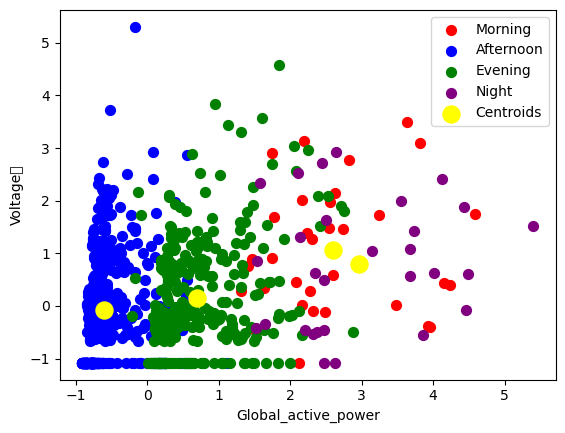

In [153]:
import matplotlib.pyplot as plt
plt.scatter(x[y_kmeans == 0, 0], x[y_kmeans == 0, 1], s = 50, c = 'red', label = 'Morning')
plt.scatter(x[y_kmeans == 1, 0], x[y_kmeans == 1, 1], s = 50, c = 'blue', label = 'Afternoon')
plt.scatter(x[y_kmeans == 2, 0], x[y_kmeans == 2, 1], s = 50, c = 'green', label = 'Evening')
plt.scatter(x[y_kmeans == 3, 0], x[y_kmeans == 3, 1], s = 50, c = 'purple', label = 'Night')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:,1], s = 150, c = 'yellow', label = 'Centroids')
plt.xlabel('Global_active_power')
plt.ylabel('Voltage	')
plt.legend( loc ="best") 

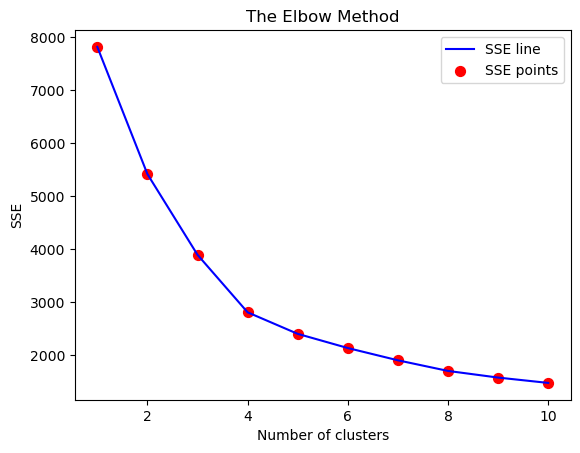

In [154]:
from sklearn.cluster import KMeans
sse = []   # Declare an array for the storage of values for Sum of Squares (SSE) Errors
for i in range(1, 11):
    kmeans = KMeans(n_clusters = i, max_iter = 300, n_init = 10, random_state = 38)                                                                                 
    kmeans.fit(x)                                                                   
    sse.append(kmeans.inertia_)                                                     
plt.plot(range(1, 11), sse, linestyle = '-', color = 'blue', label = 'SSE line')
plt.scatter(range(1, 11), sse, color = 'red', marker = 'o', s = 50, label = 'SSE points')
plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('SSE')
plt.legend()
plt.show()

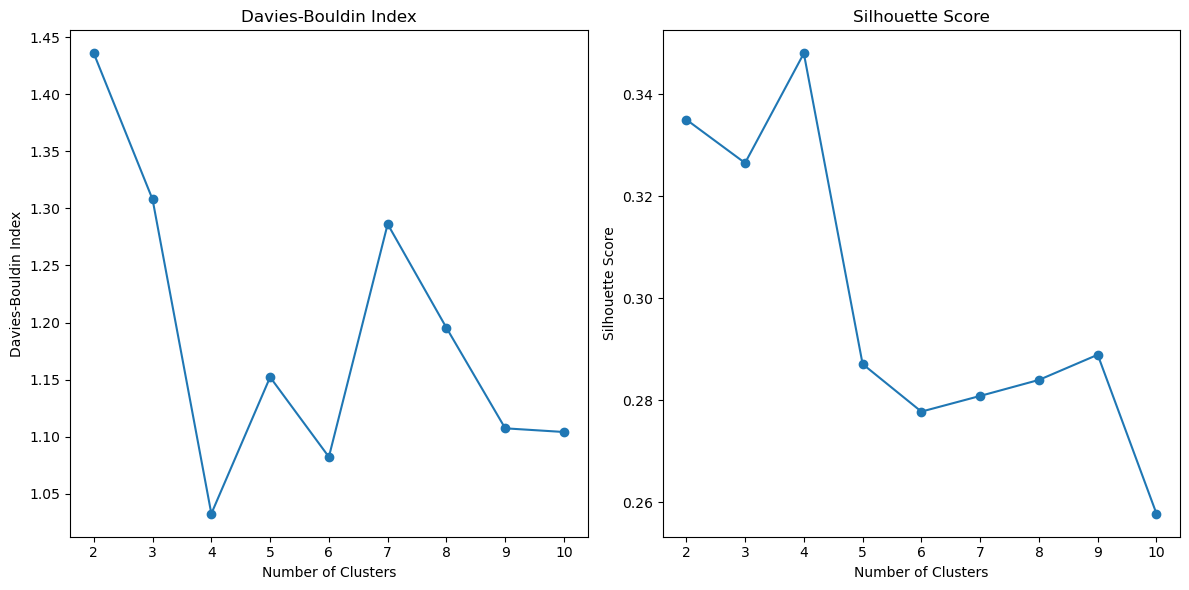

In [155]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import davies_bouldin_score
from sklearn.metrics import silhouette_score
def perform_clustering(n_clusters, data):
    agg_clustering = AgglomerativeClustering(n_clusters=n_clusters)
    labels = agg_clustering.fit_predict(df_sampled)
    db_index = davies_bouldin_score(df_sampled, labels)
    silhouette_avg = silhouette_score(df_sampled, labels)
    return db_index, silhouette_avg
cluster_range = range(2, 11)
db_scores = []
silhouette_scores=[]
for n_clusters in cluster_range:
    db_index, silhouette_avg = perform_clustering(n_clusters, df_sampled)
    db_scores.append(db_index)
    silhouette_scores.append(silhouette_avg)
plt.figure(figsize = (12, 6))
plt.subplot(1, 2, 1)
plt.plot(cluster_range, db_scores, marker = 'o')
plt.title('Davies-Bouldin Index')
plt.xlabel('Number of Clusters')
plt.ylabel('Davies-Bouldin Index')
# Plot the Silhouette method
from sklearn.metrics import silhouette_score
plt.subplot(1, 2, 2)
plt.plot(cluster_range, silhouette_scores, marker = 'o')
plt.title('Silhouette Score')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

In [112]:
from sklearn.metrics import silhouette_score
print(f'Silhouette Score(n = 4): {silhouette_score(X, y_kmeans)}')

Silhouette Score(n = 4): 0.31065660032591524


In [36]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
for n_clusters in range(2, 11):
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    labels = kmeans.fit_predict(x)
    score = silhouette_score(x, labels)
    print(f"Silhouette Score (n = {n_clusters}): {score:.4f}")

Silhouette Score (n = 2): 0.4060
Silhouette Score (n = 3): 0.4206
Silhouette Score (n = 4): 0.2897
Silhouette Score (n = 5): 0.3408
Silhouette Score (n = 6): 0.3156
Silhouette Score (n = 7): 0.3268
Silhouette Score (n = 8): 0.3045
Silhouette Score (n = 9): 0.3271
Silhouette Score (n = 10): 0.3075


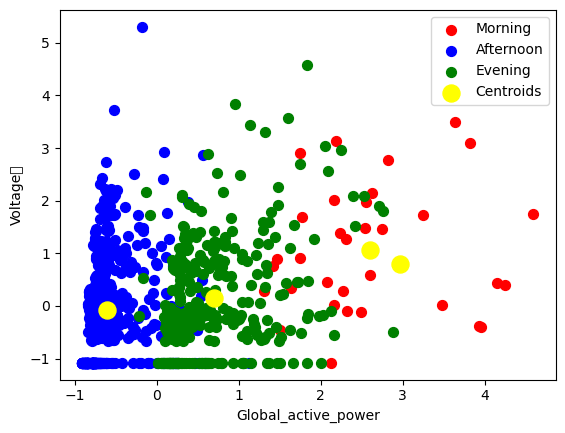

In [37]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters = 4, max_iter = 300, n_init = 10, random_state = 38)
y_kmeans = kmeans.fit_predict(x)

import matplotlib.pyplot as plt
plt.scatter(x[y_kmeans == 0, 0], x[y_kmeans == 0, 1], s = 50, c = 'red', label = 'Morning')
plt.scatter(x[y_kmeans == 1, 0], x[y_kmeans == 1, 1], s = 50, c = 'blue', label = 'Afternoon')
plt.scatter(x[y_kmeans == 2, 0], x[y_kmeans == 2, 1], s = 50, c = 'green', label = 'Evening')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:,1], s = 150, c = 'yellow', label = 'Centroids')
plt.xlabel('Global_active_power')
plt.ylabel('Voltage	')
plt.legend( loc ="best") 

K-meidod clustering 

In [38]:
from sklearn.model_selection import train_test_split
X=df.drop(["Period"], axis=1).to_numpy()
y=df["Period"].to_numpy()
print(X, y)

[[ 2.75733994  2.74294101 -1.56208752 ... -0.18589653 -0.07403413
   1.35188706]
 [ 3.77162723  2.90762424 -1.93119694 ... -0.18589653 -0.07403413
   1.2299767 ]
 [ 3.78403983  3.4748665  -2.03491364 ... -0.18589653  0.08366905
   1.35188706]
 ...
 [-0.60647647 -0.38604048  0.53970085 ... -0.18589653 -0.23173732
  -0.720589  ]
 [-0.60647647 -0.36774235  0.79289161 ... -0.18589653 -0.23173732
  -0.720589  ]
 [-0.60647647 -0.36774235  0.80814406 ... -0.18589653 -0.23173732
  -0.720589  ]] ['Evening' 'Evening' 'Evening' ... 'Night' 'Night' 'Night']


In [39]:
import sklearn.preprocessing as preproc
le=preproc.LabelEncoder()
df["Period"]=le.fit_transform(df["Period"])

In [40]:
df.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Period
0,2.757340,2.742941,-1.562088,2.878339,-0.185897,-0.074034,1.351887,1
1,3.771627,2.907624,-1.931197,3.845433,-0.185897,-0.074034,1.229977,1
2,3.784040,3.474867,-2.034914,3.845433,-0.185897,0.083669,1.351887,1
3,3.796452,3.511463,-1.897642,3.845433,-0.185897,-0.074034,1.351887,1
4,2.269702,3.749339,-1.305846,2.331721,-0.185897,-0.074034,1.351887,1


In [41]:
from pyclustering.cluster.kmedoids import kmedoids
from pyclustering.utils import calculate_distance_matrix
import numpy as np
X=np.random.rand(1500,7)
D = X[:,0:]
initial_medoids = [0, 50, 100]
kmedoids_instance = kmedoids(D, initial_medoids)
kmedoids_instance.process()
clusters = kmedoids_instance.get_clusters()
medoids = kmedoids_instance.get_medoids()
print("Clusters:", clusters)
print("Medoids:", D[medoids])

Clusters: [[0, 1, 3, 5, 6, 8, 11, 12, 29, 38, 39, 47, 48, 55, 61, 64, 65, 68, 78, 79, 84, 86, 87, 95, 97, 104, 107, 110, 111, 113, 117, 121, 125, 128, 132, 133, 134, 144, 150, 156, 162, 166, 167, 179, 180, 181, 182, 187, 189, 195, 197, 199, 200, 204, 213, 215, 223, 225, 237, 244, 251, 255, 261, 263, 265, 267, 269, 273, 275, 278, 280, 284, 289, 290, 298, 304, 308, 319, 323, 324, 325, 327, 329, 333, 334, 336, 340, 351, 353, 358, 370, 371, 375, 383, 386, 389, 396, 400, 402, 403, 407, 413, 417, 418, 419, 425, 433, 435, 436, 437, 438, 441, 454, 458, 461, 462, 467, 470, 471, 473, 477, 478, 490, 492, 495, 498, 499, 501, 503, 505, 506, 507, 511, 517, 522, 523, 530, 535, 537, 538, 541, 548, 551, 553, 554, 555, 561, 564, 569, 571, 572, 575, 585, 586, 588, 590, 592, 594, 599, 607, 609, 611, 612, 616, 617, 619, 628, 629, 634, 635, 640, 641, 642, 643, 644, 651, 657, 659, 660, 661, 664, 665, 668, 670, 671, 674, 682, 683, 688, 690, 691, 696, 702, 713, 714, 715, 716, 717, 718, 720, 721, 723, 726, 727,

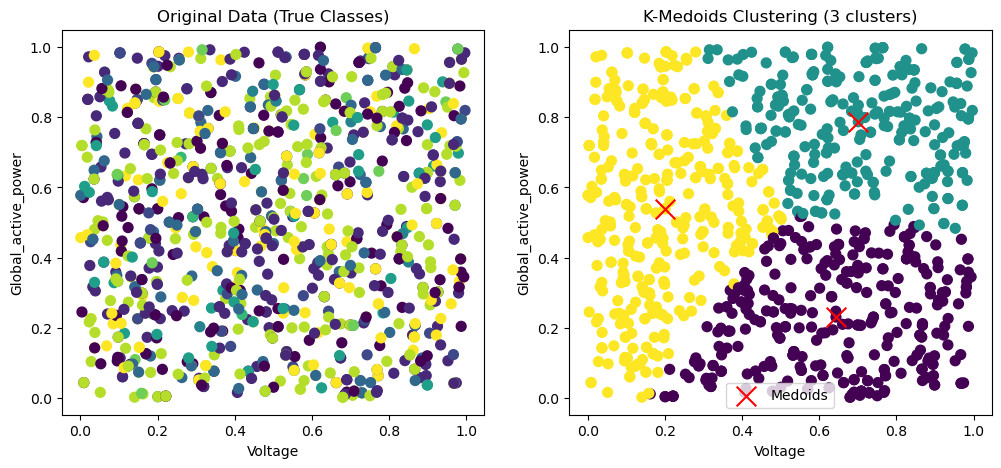

In [42]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import pairwise_distances
from pyclustering.cluster.kmedoids import kmedoids
from pyclustering.utils import calculate_distance_matrix
num_samples=1000
random_indices=np.random.choice(X.shape[0], size=num_samples, replace=True)
X_selected =X[random_indices][:,[ 0,1]]
y_selected =y[random_indices]
plt.figure(figsize=(12,5))
plt.subplot(1, 2, 1)
plt.scatter(X_selected[:, 0], X_selected[:, 1], c = labels[:num_samples], cmap = 'viridis', s = 50)
plt.xlabel("Voltage")
plt.ylabel("Global_active_power")
plt.title("Original Data (True Classes)")
distance_matrix = calculate_distance_matrix(X_selected.tolist())
initial_medoids = [0, 50, 100]  
kmedoids_instance = kmedoids(distance_matrix, initial_medoids, data_type='distance_matrix')
kmedoids_instance.process()
clusters = kmedoids_instance.get_clusters()
medoids = kmedoids_instance.get_medoids()
labels = np.zeros(len(X_selected))
for cluster_id, cluster in enumerate(clusters):
    for index in cluster:
        labels[index] = cluster_id
plt.subplot(1,2,2)
plt.scatter(X_selected[:,0], X_selected[:,1], c=labels, cmap='viridis', s=50)
plt.scatter(X_selected[medoids,0], X_selected[medoids,1], c='red', marker='x', s=200, label='Medoids')
plt.xlabel("Voltage")
plt.ylabel("Global_active_power")
plt.title("K-Medoids Clustering (3 clusters)")
plt.legend()

plt.show()

In [113]:
from sklearn.metrics import silhouette_score
print(f'Silhouette Score(n = 4): {silhouette_score( X_selected, labels)}')

Silhouette Score(n = 4): 0.3821207292722138


DBSCAN

In [66]:
from sklearn.cluster import DBSCAN
dbscan = DBSCAN(eps=0.5)
df_sampled=df.sample(n=1000, random_state=42)
dbscan.fit(df_sampled[['Global_active_power', 'Voltage']])

,"eps eps: float, default=0.5The maximum distance between two samples for one to be consideredas in the neighborhood of the other. This is not a maximum boundon the distances of points within a cluster. This is the mostimportant DBSCAN parameter to choose appropriately for your data setand distance function. Smaller values generally lead to more clusters.",0.5
,"min_samples min_samples: int, default=5The number of samples (or total weight) in a neighborhood for a point tobe considered as a core point. This includes the point itself. If`min_samples` is set to a higher value, DBSCAN will find denser clusters,whereas if it is set to a lower value, the found clusters will be moresparse.",5
,"metric metric: str, or callable, default='euclidean'The metric to use when calculating distance between instances in afeature array. If metric is a string or callable, it must be one ofthe options allowed by :func:`sklearn.metrics.pairwise_distances` forits metric parameter.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors for DBSCAN... versionadded:: 0.17 metric *precomputed* to accept precomputed sparse matrix.",'euclidean'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function... versionadded:: 0.19",None
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'The algorithm to be used by the NearestNeighbors moduleto compute pointwise distances and find nearest neighbors.'auto' will attempt to decide the most appropriate algorithmbased on the values passed to :meth:`fit` method.See :class:`~sklearn.neighbors.NearestNeighbors` documentation fordetails.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or cKDTree. This can affect the speedof the construction and query, as well as the memory requiredto store the tree. The optimal value dependson the nature of the problem.",30
,"p p: float, default=NoneThe power of the Minkowski metric to be used to calculate distancebetween points. If None, then ``p=2`` (equivalent to the Euclideandistance). When p=1, this is equivalent to Manhattan distance.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None


In [67]:
df_sampled['DBSCAN_labels'] = dbscan.labels_ 
df_sampled.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Period,DBSCAN_labels
781974,-0.649034,0.126307,0.945416,-0.653656,-0.185897,-0.231737,-0.598679,1,0
937737,2.049821,3.035711,-0.076498,2.037388,-0.185897,-0.231737,1.595708,3,0
907828,-0.753655,-0.074972,0.286510,-0.737751,-0.185897,0.083669,-0.598679,3,0
784628,2.165081,0.016519,-1.110615,2.163531,-0.185897,5.603281,1.351887,0,0
662460,0.125867,1.773140,-0.229023,0.103200,-0.185897,-0.074034,-0.720589,1,0


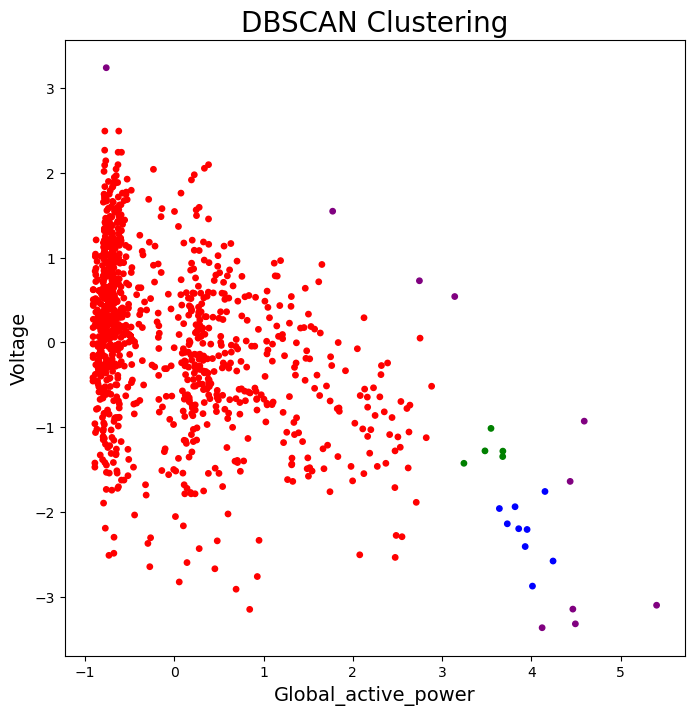

In [68]:
import matplotlib.pyplot as plt
import matplotlib
colors = ['purple','red','blue',"green"]
plt.figure(figsize = (8, 8))
plt.scatter(df_sampled["Global_active_power"], df_sampled['Voltage'], c = df_sampled['DBSCAN_labels'], cmap = matplotlib.colors.ListedColormap(colors), s = 15)
plt.title('DBSCAN Clustering',fontsize = 20)
plt.xlabel('Global_active_power', fontsize = 14)
plt.ylabel('Voltage', fontsize = 14)
plt.show()

In [69]:
from sklearn.neighbors import NearestNeighbors

neigh = NearestNeighbors(n_neighbors = 2)
nbrs = neigh.fit(df_sampled[["Global_active_power", "Voltage"]])
distances, indices = nbrs.kneighbors(df_sampled[["Global_active_power", "Voltage"]])
print(distances, indices)

[[0.         0.00932168]
 [0.         0.2267075 ]
 [0.         0.01544215]
 ...
 [0.         0.02164594]
 [0.         0.01764216]
 [0.         0.01708548]] [[  0 253]
 [  1 767]
 [  2 408]
 ...
 [997 421]
 [998 464]
 [999 399]]


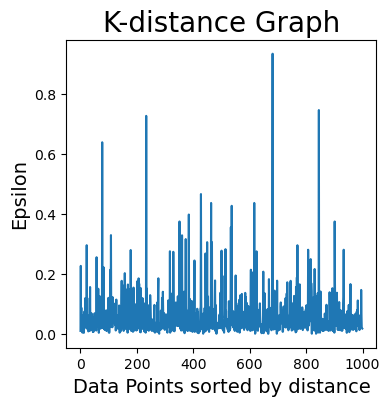

In [70]:
distances = distances[:, 1]
plt.figure(figsize = (4, 4))
plt.plot(distances)
plt.title('K-distance Graph', fontsize = 20)
plt.xlabel('Data Points sorted by distance', fontsize = 14)
plt.ylabel('Epsilon', fontsize = 14)
plt.show()

In [71]:
from sklearn.cluster import DBSCAN
dbscan_opt = DBSCAN(eps = 0.4, min_samples = 5)
dbscan_opt.fit(df_sampled[["Global_active_power", "Voltage"]])

,"eps eps: float, default=0.5The maximum distance between two samples for one to be consideredas in the neighborhood of the other. This is not a maximum boundon the distances of points within a cluster. This is the mostimportant DBSCAN parameter to choose appropriately for your data setand distance function. Smaller values generally lead to more clusters.",0.4
,"min_samples min_samples: int, default=5The number of samples (or total weight) in a neighborhood for a point tobe considered as a core point. This includes the point itself. If`min_samples` is set to a higher value, DBSCAN will find denser clusters,whereas if it is set to a lower value, the found clusters will be moresparse.",5
,"metric metric: str, or callable, default='euclidean'The metric to use when calculating distance between instances in afeature array. If metric is a string or callable, it must be one ofthe options allowed by :func:`sklearn.metrics.pairwise_distances` forits metric parameter.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors for DBSCAN... versionadded:: 0.17 metric *precomputed* to accept precomputed sparse matrix.",'euclidean'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function... versionadded:: 0.19",None
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'The algorithm to be used by the NearestNeighbors moduleto compute pointwise distances and find nearest neighbors.'auto' will attempt to decide the most appropriate algorithmbased on the values passed to :meth:`fit` method.See :class:`~sklearn.neighbors.NearestNeighbors` documentation fordetails.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or cKDTree. This can affect the speedof the construction and query, as well as the memory requiredto store the tree. The optimal value dependson the nature of the problem.",30
,"p p: float, default=NoneThe power of the Minkowski metric to be used to calculate distancebetween points. If None, then ``p=2`` (equivalent to the Euclideandistance). When p=1, this is equivalent to Manhattan distance.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None


In [72]:
df_sampled['DBSCAN_opt_labels'] = dbscan_opt.labels_
df_sampled['DBSCAN_opt_labels'].value_counts()

DBSCAN_opt_labels
 0    967
-1     20
 1      8
 2      5
Name: count, dtype: int64

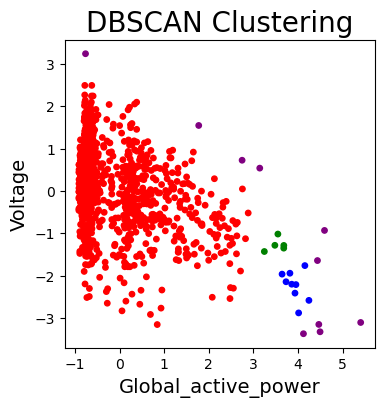

In [73]:
plt.figure(figsize = (4, 4))
plt.scatter(df_sampled["Global_active_power"], df_sampled["Voltage"], c = df_sampled['DBSCAN_labels'], cmap = matplotlib.colors.ListedColormap(colors), s = 15)
plt.title('DBSCAN Clustering', fontsize = 20)
plt.xlabel('Global_active_power', fontsize = 14)
plt.ylabel('Voltage', fontsize = 14)
plt.show()

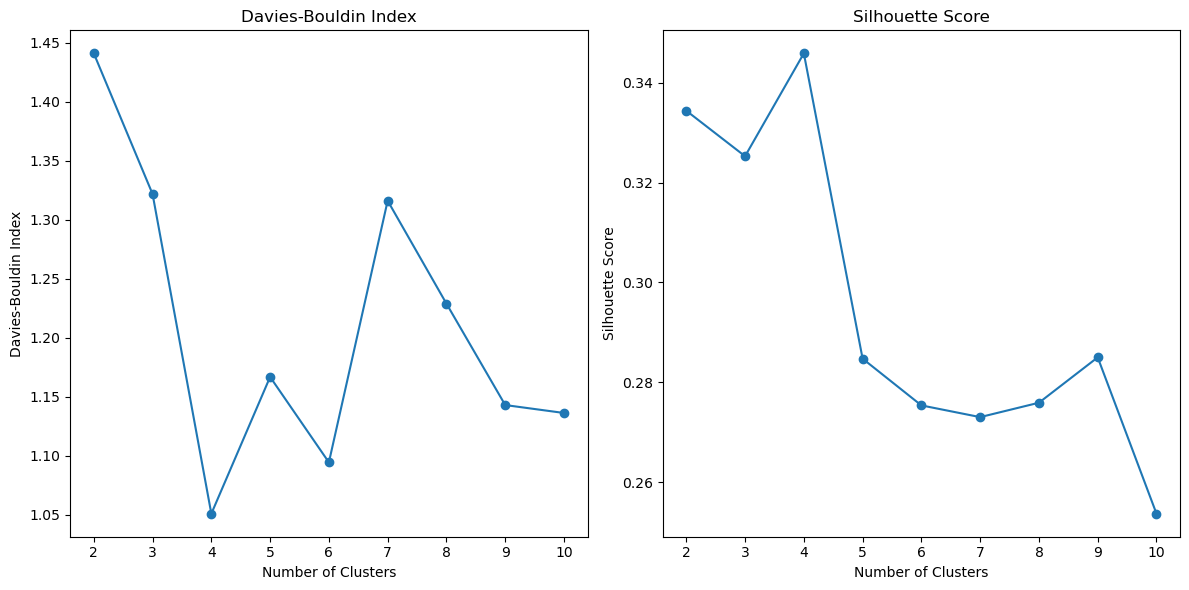

In [74]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import davies_bouldin_score
from sklearn.metrics import silhouette_score
def perform_clustering(n_clusters, data):
    agg_clustering = AgglomerativeClustering(n_clusters=n_clusters)
    labels = agg_clustering.fit_predict(df_sampled)
    db_index = davies_bouldin_score(df_sampled, labels)
    silhouette_avg = silhouette_score(df_sampled, labels)
    return db_index, silhouette_avg
cluster_range = range(2, 11)
db_scores = []
silhouette_scores=[]
for n_clusters in cluster_range:
    db_index, silhouette_avg = perform_clustering(n_clusters, df_sampled)
    db_scores.append(db_index)
    silhouette_scores.append(silhouette_avg)
plt.figure(figsize = (12, 6))
plt.subplot(1, 2, 1)
plt.plot(cluster_range, db_scores, marker = 'o')
plt.title('Davies-Bouldin Index')
plt.xlabel('Number of Clusters')
plt.ylabel('Davies-Bouldin Index')
# Plot the Silhouette method
from sklearn.metrics import silhouette_score
plt.subplot(1, 2, 2)
plt.plot(cluster_range, silhouette_scores, marker = 'o')
plt.title('Silhouette Score')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')

plt.tight_layout()
plt.show()


In [114]:
X_dbscan=df_sampled[["Global_active_power", "Voltage"]]
dbscan_labels=df_sampled["DBSCAN_labels"]
print(f'Silhouette Score(n = 4): {silhouette_score( X_dbscan, dbscan_labels)}')

Silhouette Score(n = 4): 0.5398430624739458


Hierarchical Clustering

In [80]:
from sklearn.cluster import AgglomerativeClustering
model = AgglomerativeClustering(n_clusters = 3, metric = 'euclidean')
model.fit(df_sampled[["Global_active_power", "Voltage"]])

,"n_clusters n_clusters: int or None, default=2The number of clusters to find. It must be ``None`` if``distance_threshold`` is not ``None``.",3
,"metric metric: str or callable, default=""euclidean""Metric used to compute the linkage. Can be ""euclidean"", ""l1"", ""l2"",""manhattan"", ""cosine"", or ""precomputed"". If linkage is ""ward"", only""euclidean"" is accepted. If ""precomputed"", a distance matrix is neededas input for the fit method. If connectivity is None, linkage is""single"" and affinity is not ""precomputed"" any valid pairwise distancemetric can be assigned.For an example of agglomerative clustering with different metrics, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_clustering_metrics.py`... versionadded:: 1.2",'euclidean'
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the output of the computation of the tree.By default, no caching is done. If a string is given, it is thepath to the caching directory.",None
,"connectivity connectivity: array-like, sparse matrix, or callable, default=NoneConnectivity matrix. Defines for each sample the neighboringsamples following a given structure of the data.This can be a connectivity matrix itself or a callable that transformsthe data into a connectivity matrix, such as derived from`kneighbors_graph`. Default is ``None``, i.e, thehierarchical clustering algorithm is unstructured.For an example of connectivity matrix using:class:`~sklearn.neighbors.kneighbors_graph`, see:ref:`sphx_glr_auto_examples_cluster_plot_ward_structured_vs_unstructured.py`.",None
,"compute_full_tree compute_full_tree: 'auto' or bool, default='auto'Stop early the construction of the tree at ``n_clusters``. This isuseful to decrease computation time if the number of clusters is notsmall compared to the number of samples. This option is useful onlywhen specifying a connectivity matrix. Note also that when varying thenumber of clusters and using caching, it may be advantageous to computethe full tree. It must be ``True`` if ``distance_threshold`` is not``None``. By default `compute_full_tree` is ""auto"", which is equivalentto `True` when `distance_threshold` is not `None` or that `n_clusters`is inferior to the maximum between 100 or `0.02 * n_samples`.Otherwise, ""auto"" is equivalent to `False`.",'auto'
,"linkage linkage: {'ward', 'complete', 'average', 'single'}, default='ward'Which linkage criterion to use. The linkage criterion determines whichdistance to use between sets of observation. The algorithm will mergethe pairs of cluster that minimize this criterion.- 'ward' minimizes the variance of the clusters being merged.- 'average' uses the average of the distances of each observation of the two sets.- 'complete' or 'maximum' linkage uses the maximum distances between all observations of the two sets.- 'single' uses the minimum of the distances between all observations of the two sets... versionadded:: 0.20 Added the 'single' optionFor examples comparing different `linkage` criteria, see:ref:`sphx_glr_auto_examples_cluster_plot_linkage_comparison.py`.",'ward'
,"distance_threshold distance_threshold: float, default=NoneThe linkage distance threshold at or above which clusters will not bemerged. If not ``None``, ``n_clusters`` must be ``None`` and``compute_full_tree`` must be ``True``... versionadded:: 0.21",None
,"compute_distances compute_distances: bool, default=FalseComputes distances between clusters even if `distance_threshold` is notused. This can be used to make dendrogram visualization, but introducesa computational and memory overhead... versionadded:: 0.24For an example of dendrogram visualization, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_dendrogram.py`.",False


In [81]:
df_sampled['HR_labels'] = model.labels_
df_sampled.head()

,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Period,DBSCAN_labels,DBSCAN_opt_labels,HR_labels
781974,-0.649034,0.126307,0.945416,-0.653656,-0.185897,-0.231737,-0.598679,1,0,0,1
937737,2.049821,3.035711,-0.076498,2.037388,-0.185897,-0.231737,1.595708,3,0,0,0
907828,-0.753655,-0.074972,0.286510,-0.737751,-0.185897,0.083669,-0.598679,3,0,0,1
784628,2.165081,0.016519,-1.110615,2.163531,-0.185897,5.603281,1.351887,0,0,0,2
662460,0.125867,1.773140,-0.229023,0.103200,-0.185897,-0.074034,-0.720589,1,0,0,0


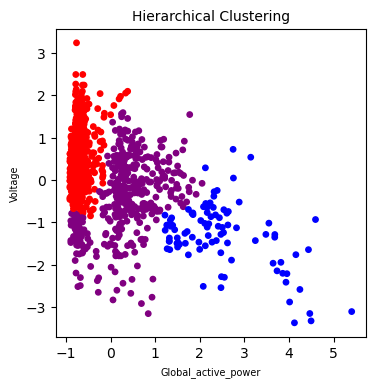

In [82]:
colors = ['purple','red','blue']
plt.figure(figsize = (4, 4))
plt.scatter(df_sampled["Global_active_power"], df_sampled["Voltage"], c = df_sampled['HR_labels'], cmap = matplotlib.colors.ListedColormap(colors), s = 15)
plt.title('Hierarchical Clustering',fontsize = 10)
plt.xlabel('Global_active_power', fontsize = 7)
plt.ylabel('Voltage', fontsize = 7)
plt.show()

FUZZY C-MEans

In [83]:
from sklearn.cluster import KMeans
import numpy as np
import skfuzzy as fuzz

# Select two features for clustering
X = df_sampled[["Global_active_power", "Voltage"]].values

In [84]:
kmeans = KMeans(n_clusters = 3, random_state = 42)
kmeans_labels = kmeans.fit_predict(X)

In [85]:
# Transpose the data matrix so that each row represents a feature and each column represents a data point. 
# The skfuzzy cmeans() function expects input in this format.

X_fcm = X.T

# Declare the number of clusters
n_clusters = 4

# Initilise the model object
cntr, u, u0, d, jm, p, fpc = fuzz.cluster.cmeans(X_fcm, c = n_clusters, m = 4, error = 0.005, maxiter = 1000, init = None, seed = 42)

# pick highest membership
fcm_labels = np.argmax(u, axis=0)

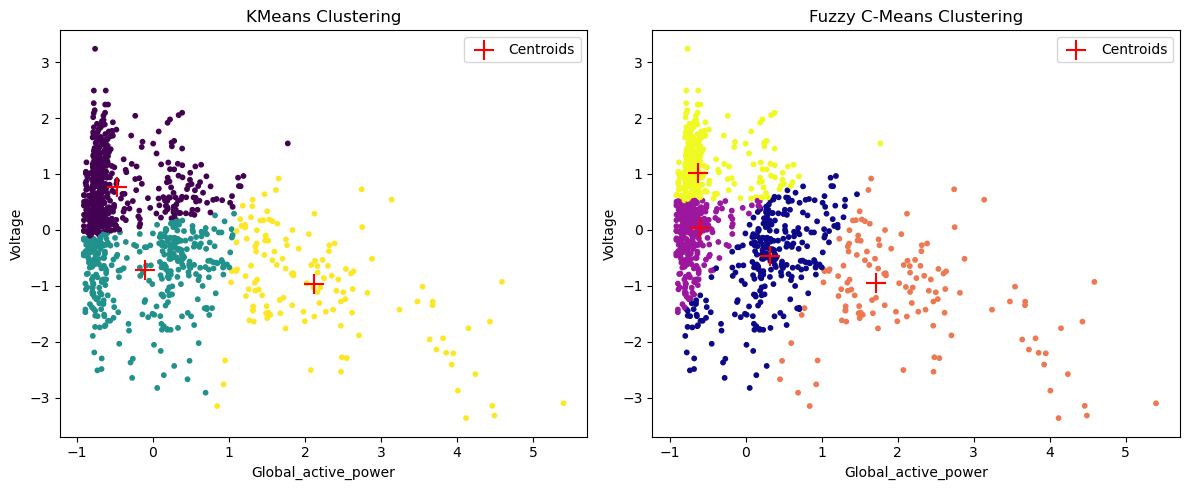

In [86]:
import matplotlib.pyplot as plt

# Plot KMeans results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X[:, 0], X[:, 1], c=kmeans_labels, cmap="viridis", s=10)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            c="red", marker="+", s=200, label="Centroids")
plt.title("KMeans Clustering")
plt.xlabel("Global_active_power")
plt.ylabel("Voltage")
plt.legend()

# Plot FCM results
plt.subplot(1, 2, 2)
plt.scatter(X[:, 0], X[:, 1], c=fcm_labels, cmap="plasma", s=10)
plt.scatter(cntr[:, 0], cntr[:, 1], c="red", marker="+", s=200, label="Centroids")
plt.title("Fuzzy C-Means Clustering")
plt.xlabel("Global_active_power")
plt.ylabel("Voltage")
plt.legend()

plt.tight_layout()
plt.show()

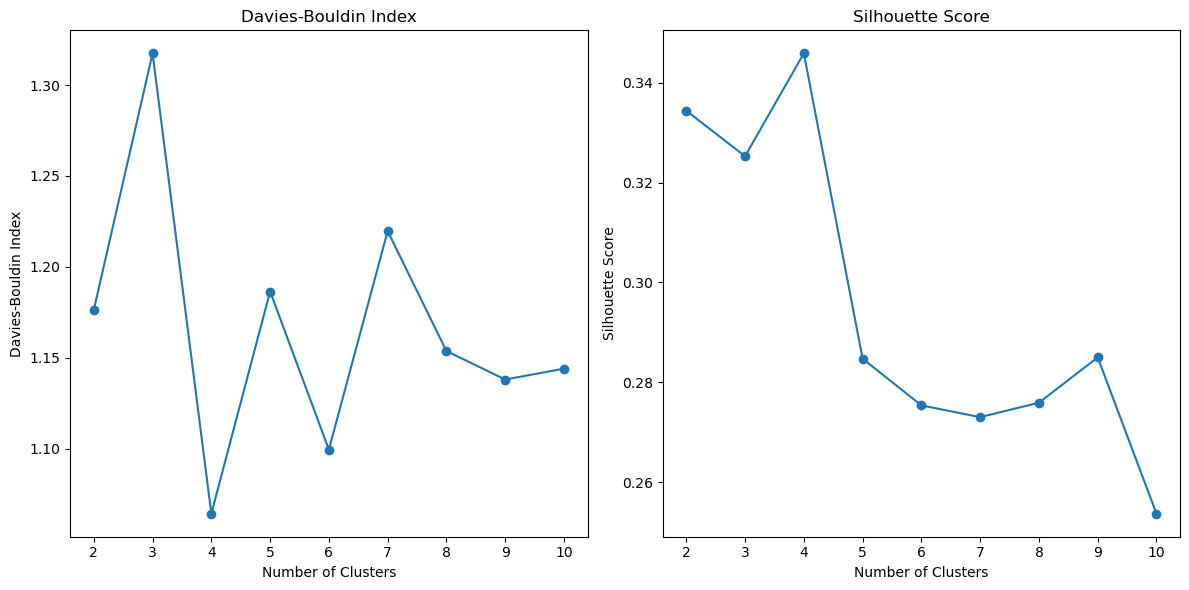

In [87]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import davies_bouldin_score, silhouette_score
def perform_clustering(n_clusters, data):
    agg_clustering = AgglomerativeClustering(n_clusters=n_clusters)
    labels = agg_clustering.fit_predict(df_sampled)
    db_index = davies_bouldin_score(df_sampled, labels)
    silhouette_avg = silhouette_score(df_sampled, labels)
    return db_index, silhouette_avg
cluster_range = range(2, 11)
db_scores = []
for n_clusters in cluster_range:
    db_index, silhouette_avg = perform_clustering(n_clusters, df_sampled)
    db_scores.append(db_index)
plt.figure(figsize = (12, 6))
plt.subplot(1, 2, 1)
plt.plot(cluster_range, db_scores, marker = 'o')
plt.title('Davies-Bouldin Index')
plt.xlabel('Number of Clusters')
plt.ylabel('Davies-Bouldin Index')
# Plot the Silhouette method
from sklearn.metrics import silhouette_score
plt.subplot(1, 2, 2)
plt.plot(cluster_range, silhouette_scores, marker = 'o')
plt.title('Silhouette Score')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

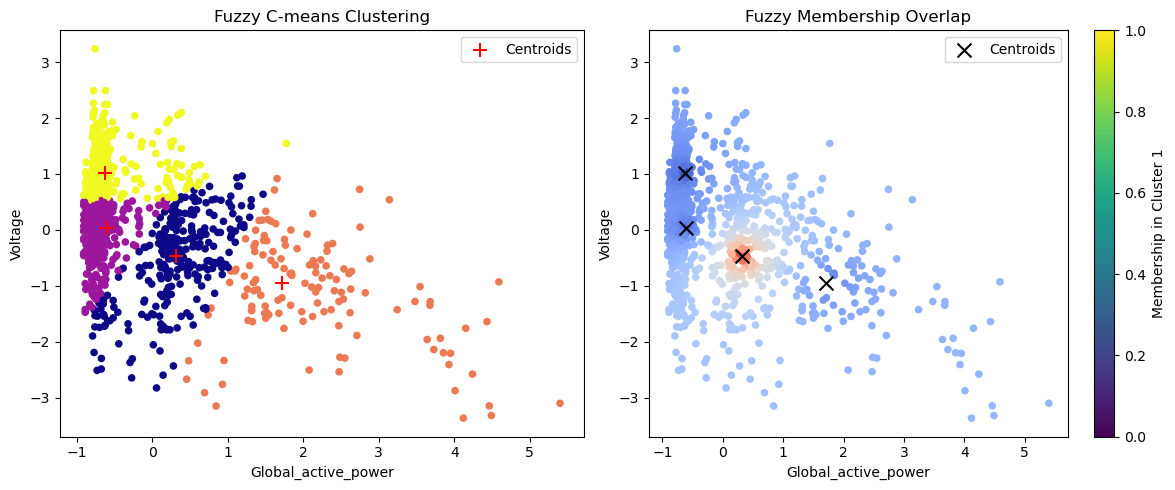

In [88]:
plt.figure(figsize=(12, 5))

# Subplot 1: Hard assignment (like KMeans)
plt.subplot(1, 2, 1)
fcm_labels = np.argmax(u, axis = 0)
plt.scatter(X[:, 0], X[:, 1], c = fcm_labels, cmap = "plasma", s = 20)
plt.scatter(cntr[:, 0], cntr[:, 1], c = "red", marker = "+", s = 100, label = "Centroids")
plt.title("Fuzzy C-means Clustering")
plt.xlabel("Global_active_power")
plt.ylabel("Voltage")
plt.legend()

# Subplot 2: Membership strength (shows overlap)
plt.subplot(1, 2, 2)
# Use membership in cluster 1 as color intensity
plt.scatter(X[:, 0], X[:, 1], c = u[0], cmap = "coolwarm", s = 20)
plt.scatter(cntr[:, 0], cntr[:, 1], c = "black", marker = "x", s = 100, label = "Centroids")
plt.title("Fuzzy Membership Overlap")
plt.xlabel("Global_active_power")
plt.ylabel("Voltage")
cbar = plt.colorbar()
cbar.set_label("Membership in Cluster 1")
plt.legend()

plt.tight_layout()
plt.show()

In [89]:
import numpy as np

# Threshold on max membership
threshold = 0.6
max_memberships = np.max(u, axis=0)
overlap_mask = max_memberships <= threshold

# Identify overlapped points by either method
overlap_points = X[overlap_mask]

print(f"Overlap (max membership ≤ {threshold}): {len(overlap_points)} points")

# Example: print a few overlapped points with their memberships
for i, (point, mem) in enumerate(zip(X[overlap_mask], u.T[overlap_mask])):
    if i < 10:
        print(f"Point {point} -> memberships {mem}")

Overlap (max membership ≤ 0.6): 897 points
Point [ 2.04982136 -0.07649835] -> memberships [0.2487139  0.18998078 0.38144597 0.17985935]
Point [-0.75365452  0.28651009] -> memberships [0.17175741 0.4719867  0.10449737 0.25175851]
Point [ 2.16508128 -1.11061483] -> memberships [0.20079897 0.15100474 0.51203022 0.13616607]
Point [ 0.12586732 -0.22902291] -> memberships [0.45462873 0.24281796 0.14199574 0.16055757]
Point [-0.86536798  0.95456764] -> memberships [0.14197734 0.22118018 0.09836975 0.53847274]
Point [0.19147682 0.36887335] -> memberships [0.29273352 0.28844839 0.16388187 0.25493622]
Point [0.29964382 0.06992522] -> memberships [0.3694343  0.26003116 0.1681049  0.20242963]
Point [-0.23409827  0.90881027] -> memberships [0.18491916 0.24952799 0.1241593  0.44139355]
Point [ 0.70925984 -0.07954885] -> memberships [0.3879016  0.21598303 0.21519329 0.18092208]
Point [-0.69159149  1.28402067] -> memberships [0.14640237 0.20192832 0.10592963 0.54573967]


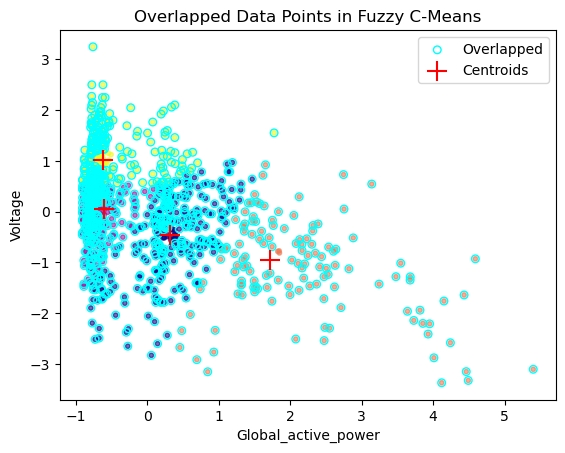

In [90]:
plt.scatter(X[:, 0], X[:, 1], c=np.argmax(u, axis=0), cmap = "plasma", s = 10, alpha = 0.6)
plt.scatter(overlap_points[:, 0], overlap_points[:, 1],
            facecolors="none",  edgecolors="cyan", s=30, linewidths=1, label="Overlapped")
plt.scatter(cntr[:, 0], cntr[:, 1], c="red", marker="+", s=200, label="Centroids")
plt.title("Overlapped Data Points in Fuzzy C-Means")
plt.xlabel("Global_active_power")
plt.ylabel("Voltage")
plt.legend()
plt.show()

In [115]:
print(f'Silhouette Score(n = 4): {silhouette_score( X, kmeans_labels)}')

Silhouette Score(n = 4): 0.3966870807746171


Time series

In [156]:
import pandas as pd
import warnings 
warnings.filterwarnings("ignore")
df_1=pd.read_csv("individual household power consumption.csv", sep=";")

In [157]:
df_1.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.0


In [158]:
df_1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 9 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   Date                   1048575 non-null  object 
 1   Time                   1048575 non-null  object 
 2   Global_active_power    1048575 non-null  object 
 3   Global_reactive_power  1048575 non-null  object 
 4   Voltage                1048575 non-null  object 
 5   Global_intensity       1048575 non-null  object 
 6   Sub_metering_1         1048575 non-null  object 
 7   Sub_metering_2         1048575 non-null  object 
 8   Sub_metering_3         1044506 non-null  float64
dtypes: float64(1), object(8)
memory usage: 72.0+ MB


In [159]:
df_1.isnull().sum()

Date                        0
Time                        0
Global_active_power         0
Global_reactive_power       0
Voltage                     0
Global_intensity            0
Sub_metering_1              0
Sub_metering_2              0
Sub_metering_3           4069
dtype: int64

In [160]:
mv=["nan", "...,", "?"]

In [161]:
df_1=pd.read_csv("individual household power consumption.csv",sep=";", na_values=mv)

In [162]:
df_1.isnull().sum()

Date                        0
Time                        0
Global_active_power      4069
Global_reactive_power    4069
Voltage                  4069
Global_intensity         4069
Sub_metering_1           4069
Sub_metering_2           4069
Sub_metering_3           4069
dtype: int64

In [163]:
Column_drop=["Date"]+list(df_1.columns[-6:])
df_1=df_1.drop(columns=Column_drop)

In [164]:
df_1.head()

,Time,Global_active_power
0,17:24:00,4.216
1,17:25:00,5.360
2,17:26:00,5.374
3,17:27:00,5.388
4,17:28:00,3.666


In [165]:

df_1["Global_active_power"].fillna(df_1["Global_active_power"].median(), inplace=True)

In [166]:
df_1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 2 columns):
 #   Column               Non-Null Count    Dtype  
---  ------               --------------    -----  
 0   Time                 1048575 non-null  object 
 1   Global_active_power  1048575 non-null  float64
dtypes: float64(1), object(1)
memory usage: 16.0+ MB


In [167]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

df_1["Datetime"]=pd.to_datetime(df_1["Time"])
df_1.set_index("Datetime", inplace=True)

<Axes: xlabel='Datetime'>

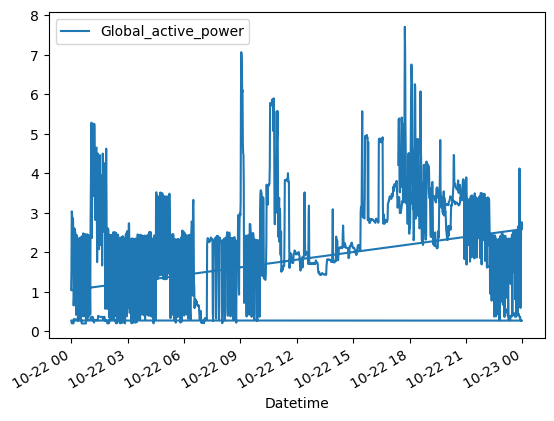

In [168]:
sample_df_2=df_1.head(2000)
sample_df_2.plot()

In [169]:

sample_df_2.index=pd.to_datetime(sample_df_2.index, format="%H", errors="coerce")

sample_df_2.index=sample_df_2.index.strftime("%H")

<Axes: xlabel='Datetime'>

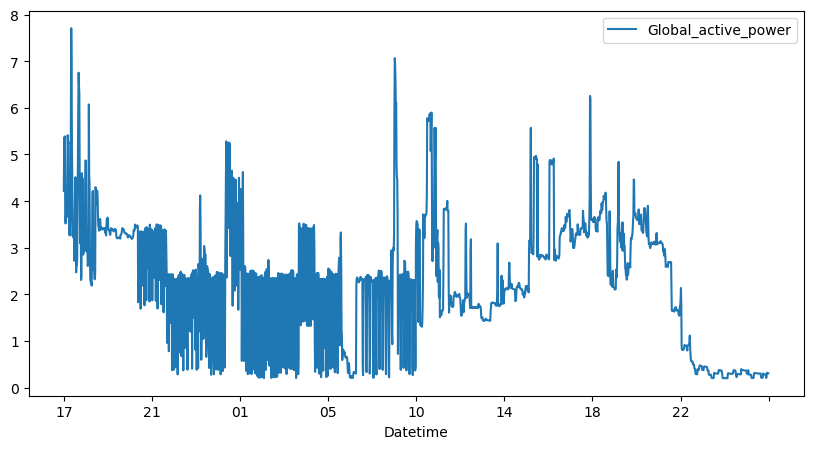

In [170]:
sample_df_2.plot(figsize=(10,5))

In [171]:
sample_df_2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2000 entries, 17 to 02
Data columns (total 2 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Time                 2000 non-null   object 
 1   Global_active_power  2000 non-null   float64
dtypes: float64(1), object(1)
memory usage: 111.4+ KB


In [172]:
sample_df_2.head()

,Time,Global_active_power
Datetime,,
17,17:24:00,4.216
17,17:25:00,5.360
17,17:26:00,5.374
17,17:27:00,5.388
17,17:28:00,3.666


In [173]:
sample_df_2=sample_df_2.drop("Time", axis=1)


In [174]:
sample_df_2.head()

,Global_active_power
Datetime,
17,4.216
17,5.360
17,5.374
17,5.388
17,3.666


<Axes: xlabel='Datetime'>

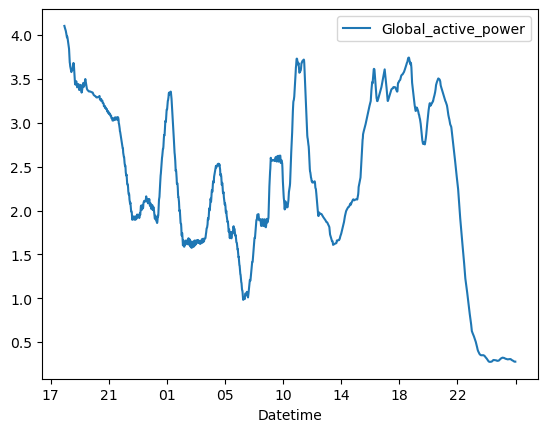

In [175]:
sample_df_2.rolling(window = 60).mean().plot()

Stationary

<Axes: xlabel='Datetime'>

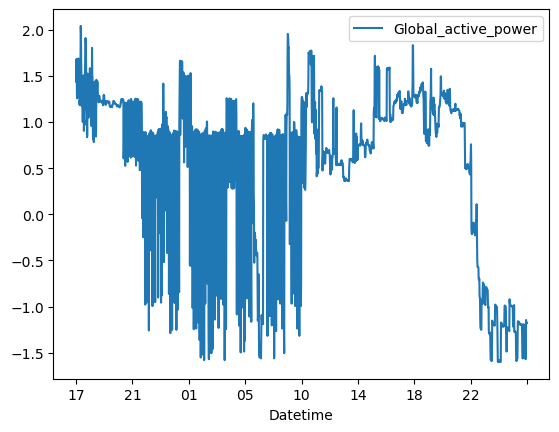

In [176]:
import numpy as np
# One method to get rid of time varying variance is to do a power or log transformation that punishes larger values
# more than smaller values
log_sample_df_2=sample_df_2.apply(lambda x: np.log(x))
log_sample_df_2.plot()

Seasonality

<Axes: xlabel='Datetime'>

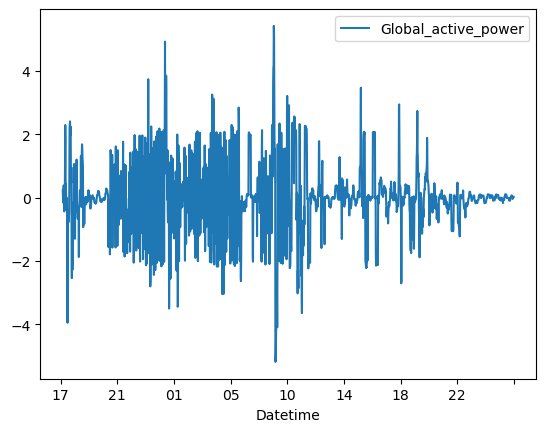

In [177]:
# shift() Shift index by desired number of periods with an optional time `freq`.
# By default It shifts 1 period, check the example details using shift + tab
(sample_df_2 - sample_df_2.shift(10)).plot()

<Axes: xlabel='Datetime'>

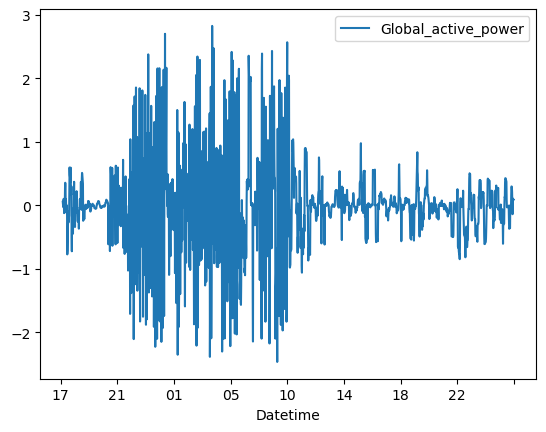

In [178]:
log_df_diff = log_sample_df_2 - log_sample_df_2.shift(10)
log_df_diff.plot()


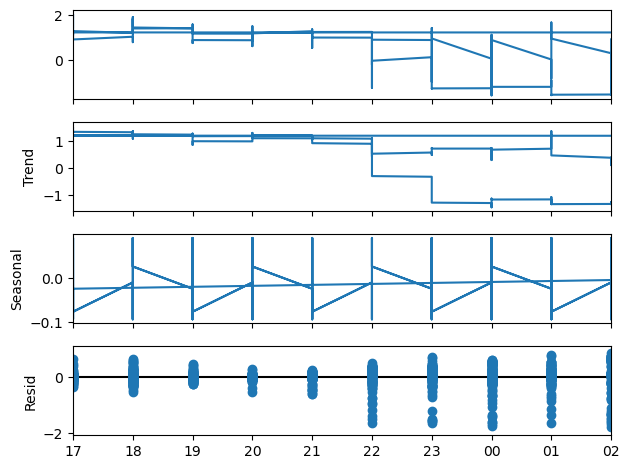

In [179]:
from statsmodels.tsa.seasonal import seasonal_decompose
from matplotlib import pyplot
# interpolate() means replacement of values if some data is missed
# log_passengers.interpolate(inplace = True)
log_sample_df_2.interpolate(inplace = True)

# decompose the data using seasonal_decompose() function
decomposition = seasonal_decompose(log_sample_df_2, model = 'additive', period=24)

# The additive model is Y[t] = T[t] + S[t] + e[t]

# The multiplicative model is Y[t] = T[t] * S[t] * e[t]

# Plot the function using plot()
decomposition.plot()
pyplot.show()

Dickey Fuller test

In [180]:
series = sample_df_2['Global_active_power'].values
print(series)

[4.216 5.36  5.374 ... 0.31  0.308 0.308]


In [181]:
from statsmodels.tsa.stattools import adfuller
series=sample_df_2["Global_active_power"].values
ad_fuller_result = adfuller(series)
print(f'ADF Statistic: {ad_fuller_result[0]}')
print(f'p-value: {ad_fuller_result[1]}')

ADF Statistic: -3.2671069679812117
p-value: 0.016414363460991514


ACF and PACF Plots

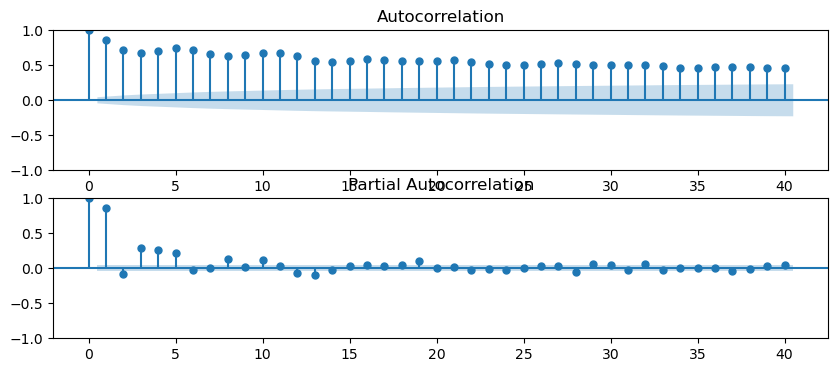

In [182]:
import statsmodels.api as sm
fig = plt.figure(figsize = (10, 4))
ax1 = fig.add_subplot(211)
fig = sm.graphics.tsa.plot_acf(sample_df_2['Global_active_power'].dropna(), lags = 40, ax = ax1)
ax2 = fig.add_subplot(212)
fig = sm.graphics.tsa.plot_pacf(sample_df_2['Global_active_power'].dropna(), lags = 40, ax = ax2)
plt.show()

In [185]:
import warnings 
warnings.filterwarnings("ignore")

from statsmodels.tsa.arima.model import ARIMA

aicVal = []
for d in range(1, 3):
    for ari in range(0, 3):
        for maj in range(0, 3):
            try:
                arima_obj = ARIMA(sample_df_2['Global_active_power'], order = (ari, d, maj))
                arima_obj_fit = arima_obj.fit()
                aicVal.append([ari, d, maj, arima_obj_fit.aic])
            except ValueError:
                pass
for val in aicVal:
    print(f"ARIMA({val[0]}, {val[1]}, {val[2]}) -> AIC: {val[3]}")

ARIMA(0, 1, 0) -> AIC: 4187.854051287814
ARIMA(0, 1, 1) -> AIC: 4189.397355553867
ARIMA(0, 1, 2) -> AIC: 3737.052300427995
ARIMA(1, 1, 0) -> AIC: 4189.712332270272
ARIMA(1, 1, 1) -> AIC: 3871.2379338754845
ARIMA(1, 1, 2) -> AIC: 3705.6565945568577
ARIMA(2, 1, 0) -> AIC: 3927.747831914018
ARIMA(2, 1, 1) -> AIC: 3645.561508383171
ARIMA(2, 1, 2) -> AIC: 3641.883635930582
ARIMA(0, 2, 0) -> AIC: 5553.393078362258
ARIMA(0, 2, 1) -> AIC: 4196.351312345489
ARIMA(0, 2, 2) -> AIC: 4197.835070571593
ARIMA(1, 2, 0) -> AIC: 5342.297787153515
ARIMA(1, 2, 1) -> AIC: 4198.186194035157
ARIMA(1, 2, 2) -> AIC: 4165.847727723602
ARIMA(2, 2, 0) -> AIC: 5063.218994522835
ARIMA(2, 2, 1) -> AIC: 3936.93321951858
ARIMA(2, 2, 2) -> AIC: 3656.377352156495


In [187]:
best_model = min(aicVal, key=lambda x: x[3])
print(f"\nMinimum AIC value: {best_model[3]:.2f}")
print(f"Best model: ARIMA({best_model[0]}, {best_model[1]}, {best_model[2]})")


Minimum AIC value: 3641.88
Best model: ARIMA(2, 1, 2)


SARIMA model

In [188]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
series=sample_df_2["Global_active_power"].values
best_model = SARIMAX(sample_df_2['Global_active_power'], order = (2, 1, 2), seasonal_order = (2, 1, 2, 24)).fit(dis = -1)
print(best_model.summary())

                                     SARIMAX Results                                      
Dep. Variable:                Global_active_power   No. Observations:                 2000
Model:             SARIMAX(2, 1, 2)x(2, 1, 2, 24)   Log Likelihood               -1840.604
Date:                            Thu, 22 Oct 2026   AIC                           3699.209
Time:                                    16:05:23   BIC                           3749.504
Sample:                                         0   HQIC                          3717.688
                                           - 2000                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6617      0.049     13.572      0.000       0.566       0.757
ar.L2         -0.4557      0.033   

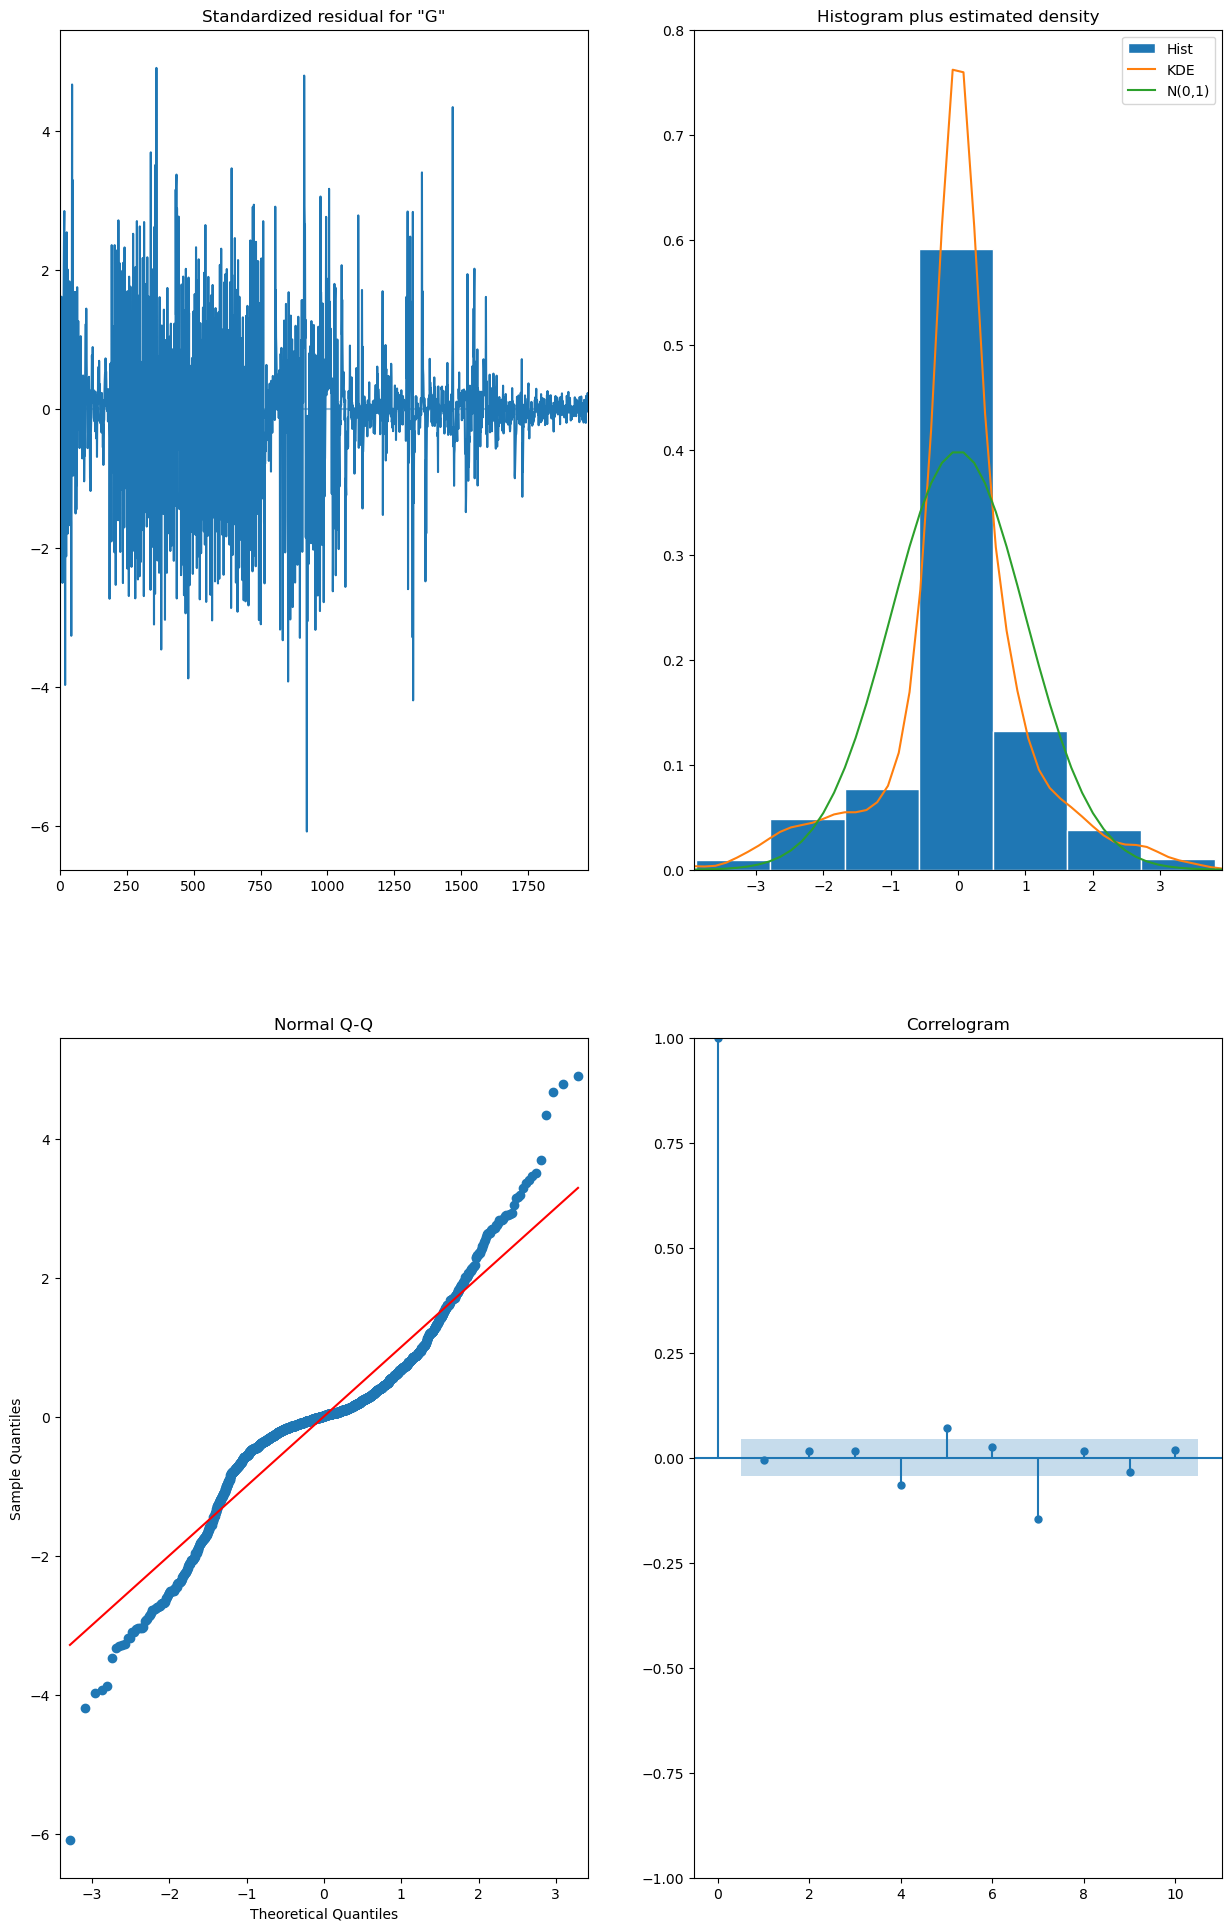

In [189]:
best_model.plot_diagnostics(figsize = (15, 24))
plt.show()

In [193]:
sample_df_2.head()

,Global_active_power
Datetime,
17,4.216
17,5.360
17,5.374
17,5.388
17,3.666


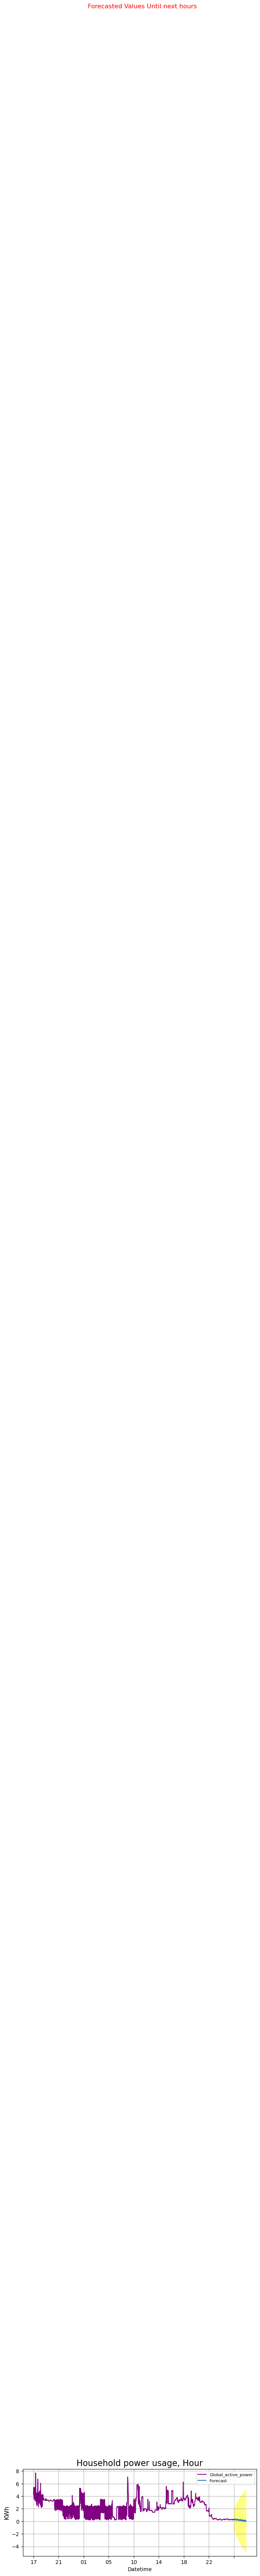

In [191]:

forecast_values = best_model.get_forecast(steps = 120)

forecast_ci = forecast_values.conf_int()

ax = sample_df_2.plot(y = 'Global_active_power', figsize = (14, 6), legend = True, color = 'purple' )
forecast_values.predicted_mean.plot(ax = ax, label = 'Forecast', figsize = (8, 3), grid = True)

ax.fill_between(forecast_ci.index,
                forecast_ci.iloc[: , 0],
                forecast_ci.iloc[: , 1], color = 'yellow', alpha = .5) # alpha controls the transparency (opacity) of the shaded area.
plt.title('Household power usage, Hour', size = 16)
plt.ylabel('KWh', size = 12)
plt.legend(loc = 'upper right', prop = {'size': 8})
ax.axes.get_xaxis().set_visible(True)
# annotation
ax.text(540, 400, 'Forecasted Values Until next hours', fontsize = 12,  color = 'red')
plt.show()

In [192]:
train = sample_df_2[:int(0.85 * (len(sample_df_2)))]
test  = sample_df_2[int(0.85 * (len(sample_df_2))):]

train.shape, test.shape

((1700, 1), (300, 1))

In [193]:
train.head()

,Global_active_power
Datetime,
17,4.216
17,5.360
17,5.374
17,5.388
17,3.666


In [194]:
start = len(train)
end   = len(train) + len(test) - 1
predictions = best_model.predict(start = start, end = end, dynamic = False, typ = 'levels').rename('SARIMA Predictions')
print(predictions)

Datetime
21    3.131157
21    2.991516
21    3.107688
21    2.911634
21    2.909199
        ...   
02    0.324599
02    0.278919
02    0.171713
02    0.270583
02    0.270547
Name: SARIMA Predictions, Length: 300, dtype: float64


In [195]:
from itertools import product
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.metrics import median_absolute_error, mean_squared_log_error
evaluation_results = pd.DataFrame({'r2_score': r2_score(test['Global_active_power'], predictions)}, index = [0])
evaluation_results['mean_absolute_error'] = mean_absolute_error(test['Global_active_power'], predictions)
evaluation_results['mean_squared_error'] = mean_squared_error(test['Global_active_power'], predictions)
evaluation_results['root_mean_squared_error'] = np.sqrt(mean_squared_error(test['Global_active_power'], predictions))
evaluation_results['mean_absolute_percentage_error'] = np.mean(np.abs(predictions - test['Global_active_power'])
                                                               /np.abs(test['Global_active_power']))*100 
evaluation_results

,r2_score,mean_absolute_error,mean_squared_error,root_mean_squared_error,mean_absolute_percentage_error
0,0.973976,0.075558,0.014195,0.119141,15.369667


Triple exponetial

In [196]:
import esFunctions as es
%matplotlib inline
from matplotlib import axes
es.initialize_T(sample_df_2['Global_active_power'], 24)

-0.5694166666666667

In [197]:
es.initialize_seasonalilty(sample_df_2['Global_active_power'], 24) 

{0: np.float64(-0.0076726907630522345),
 1: np.float64(-0.009769076305220881),
 2: np.float64(0.07774899598393575),
 3: np.float64(0.13456827309236954),
 4: np.float64(0.07719477911646583),
 5: np.float64(-0.07208232931726907),
 6: np.float64(-0.07085341365461845),
 7: np.float64(-0.021455823293172718),
 8: np.float64(-0.02637148594377513),
 9: np.float64(-0.029528112449799238),
 10: np.float64(0.012062248995983908),
 11: np.float64(-0.0843232931726908),
 12: np.float64(-0.06509437751004021),
 13: np.float64(-0.0676244979919679),
 14: np.float64(0.04668875502008031),
 15: np.float64(0.02292971887550197),
 16: np.float64(-0.016612449799196807),
 17: np.float64(-0.02280522088353416),
 18: np.float64(0.029604417670682663),
 19: np.float64(-0.0076485943775100595),
 20: np.float64(0.00627911646586344),
 21: np.float64(-0.013455823293172716),
 22: np.float64(0.11235140562248995),
 23: np.float64(-0.004130522088353437)}

In [210]:
sample_df_2['TEF001'] = es.triple_exp_smoothing(sample_df_2['Global_active_power'], 12, 0, 0, 1)
sample_df_2['TEF010'] = es.triple_exp_smoothing(sample_df_2['Global_active_power'], 12, 0, 1, 0)
sample_df_2['TEF100'] = es.triple_exp_smoothing(sample_df_2['Global_active_power'], 12, 1, 0, 0)

In [211]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt
def calculate_accuracy(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return mse, mae, mape

In [212]:
sample_df_2['TEF110'] = es.triple_exp_smoothing(sample_df_2['Global_active_power'], 12, 1, 1, 0)  # α=1, β=1, γ=0
sample_df_2['TEF101'] = es.triple_exp_smoothing(sample_df_2['Global_active_power'], 12, 1, 0, 1)  # α=1, β=0, γ=1
sample_df_2['TEF011'] = es.triple_exp_smoothing(sample_df_2['Global_active_power'], 12, 0, 1, 1)  # α=0, β=1, γ=1

mse110, mae110, mape110 = calculate_accuracy(sample_df_2['Global_active_power'], sample_df_2['TEF110'])
mse101, mae101, mape101 = calculate_accuracy(sample_df_2['Global_active_power'], sample_df_2['TEF101'])
mse011, mae011, mape011 = calculate_accuracy(sample_df_2['Global_active_power'], sample_df_2['TEF011'])

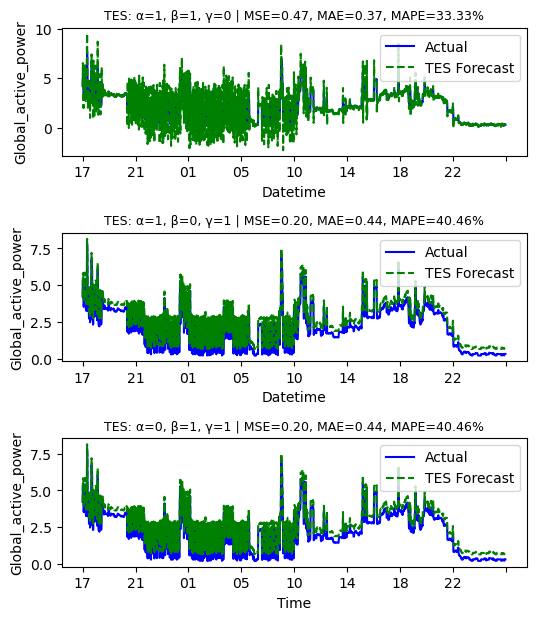

In [213]:
# --- Plot ---
fig = plt.figure(figsize=(6, 7))
fig.subplots_adjust(hspace=0.6)

# TES α=1, β=1, γ=0
ax = fig.add_subplot(3, 1, 1)
sample_df_2['Global_active_power'].plot(color='b', linestyle='-', ax=ax, label="Actual")
sample_df_2['TEF110'].plot(color='g', linestyle='--', ax=ax, label="TES Forecast")
ax.set_title(f"TES: α=1, β=1, γ=0 | MSE={mse110:.2f}, MAE={mae110:.2f}, MAPE={mape110:.2f}%", fontsize=9)
ax.set_ylabel("Global_active_power")
ax.legend()

# TES α=1, β=0, γ=1
ax = fig.add_subplot(3, 1, 2)
sample_df_2['Global_active_power'].plot(color='b', linestyle='-', ax=ax, label="Actual")
sample_df_2['TEF101'].plot(color='g', linestyle='--', ax=ax, label="TES Forecast")
ax.set_title(f"TES: α=1, β=0, γ=1 | MSE={mse101:.2f}, MAE={mae101:.2f}, MAPE={mape101:.2f}%", fontsize=9)
ax.set_ylabel("Global_active_power")
ax.legend()

# TES α=0, β=1, γ=1
ax = fig.add_subplot(3, 1, 3)
sample_df_2['Global_active_power'].plot(color='b', linestyle='-', ax=ax, label="Actual")
sample_df_2['TEF011'].plot(color='g', linestyle='--', ax=ax, label="TES Forecast")
ax.set_title(f"TES: α=0, β=1, γ=1 | MSE={mse011:.2f}, MAE={mae011:.2f}, MAPE={mape011:.2f}%", fontsize=9)
ax.set_xlabel("Time")
ax.set_ylabel("Global_active_power")
ax.legend()

plt.show()

Holt-Winters Exponential Smoothing

In [214]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing as HWES

In [215]:
sample_df_2_train = sample_df_2.iloc[:-24]
sample_df_2_test = sample_df_2.iloc[-24:]     
sample_df_2_train.shape, sample_df_2_test.shape

((1976, 9), (24, 9))

In [216]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing as HWES
model = HWES(sample_df_2_train["Global_active_power"], seasonal_periods = 24, trend = 'add', seasonal = 'add')
fitted = model.fit()

In [217]:
print(fitted.summary())

                       ExponentialSmoothing Model Results                       
Dep. Variable:      Global_active_power   No. Observations:                 1976
Model:             ExponentialSmoothing   SSE                            941.453
Optimized:                         True   AIC                          -1409.016
Trend:                         Additive   BIC                          -1252.529
Seasonal:                      Additive   AICC                         -1408.060
Seasonal Periods:                    24   Date:                 Thu, 22 Oct 2026
Box-Cox:                          False   Time:                         16:16:47
Box-Cox Coeff.:                    None                                         
                          coeff                 code              optimized      
---------------------------------------------------------------------------------
smoothing_level               1.0000000                alpha                 True
smoothing_trend          

<Axes: title={'center': 'Holt Winters Triple Exponential Smoothing: Additive and Multiplicative Seasonality'}, xlabel='Datetime'>

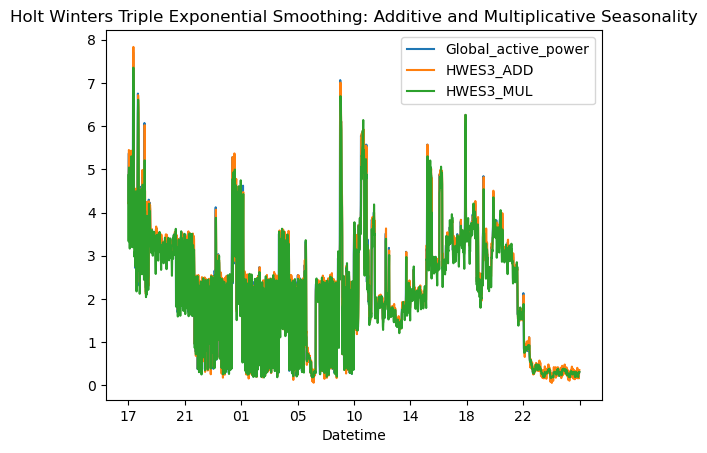

In [218]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing 
sample_df_2['HWES3_ADD'] = ExponentialSmoothing(sample_df_2['Global_active_power'], 
                                               trend = 'add', seasonal = 'add', seasonal_periods = 24).fit().fittedvalues

sample_df_2['HWES3_MUL'] = ExponentialSmoothing(sample_df_2['Global_active_power'], 
                                               trend = 'mul', seasonal = 'mul', seasonal_periods = 24).fit().fittedvalues

sample_df_2[['Global_active_power','HWES3_ADD','HWES3_MUL']].plot(
                                  title = 'Holt Winters Triple Exponential Smoothing: Additive and Multiplicative Seasonality')

Text(0.5, 1.0, 'Train, Test and Predicted Test using Holt Winters')

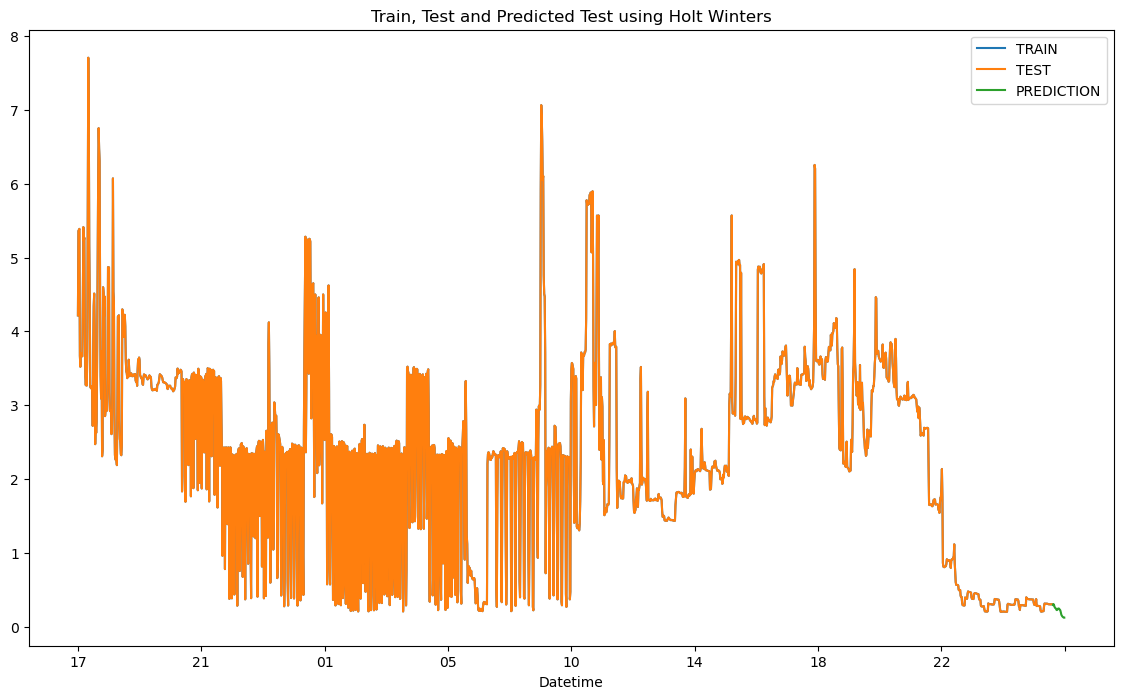

In [219]:
fitted_model = ExponentialSmoothing(sample_df_2_train['Global_active_power'],
                                    trend = 'mul', seasonal = 'mul', seasonal_periods = 24).fit()

test_predictions = fitted_model.forecast(24)

sample_df_2_train['Global_active_power'].plot(legend = True, label = 'TRAIN')
sample_df_2_train['Global_active_power'].plot(legend = True, label = 'TEST', figsize = (14, 8))
test_predictions.plot(legend = True, label = 'PREDICTION')

plt.title('Train, Test and Predicted Test using Holt Winters')